# Taller N.º 6 — PySpark DataFrames sobre el clúster

**Sesión 22 · Big Data 2026-II · Universidad Externado de Colombia**

**Carácter del taller:** formativo. Su formato —observación del portal de Spark aclada a valores propios— es el mismo que usará el Examen II.

**Qué se registra y dónde:** cada ejecución de este notebook tiene una celda de código y, justo después, una nota indicando qué anotar en el documento en Word.

## Antes de empezar: por qué los jobs aparecen etiquetados

Van a notar que cada celda de código incluye una línea como esta:

```python
sc.setJobGroup("E4", "E4 - groupBy + agg + orderBy con shuffle")
```

Esto **no es contenido nuevo del curso** y no se evalúa como tal. Es una herramienta de organización, y existe por un problema muy concreto: cuando Spark reporta un job en la pestaña *Jobs* del portal, su descripción por defecto es genérica —algo como `showString at NativeMethodAccessorImpl.java:0`— y **esa descripción se repite igual entre ejecuciones completamente distintas**. Sin más contexto, no hay forma de saber, mirando solo la lista de jobs, cuál corresponde a cuál punto del taller.

Hay además otro motivo por el que esto importa en esta sesión: varias de las acciones que van a ejecutar **generan dos Job ID, no uno**. Con siete ejecuciones y ese comportamiento, es fácil perder la cuenta de cuál es cuál si no hay una etiqueta visible.

`setJobGroup(id, descripción)` simplemente le pone un nombre a todo lo que se ejecute después de esa línea, hasta la siguiente. En el portal, ese nombre aparece en la columna **Description** de la pestaña *Jobs*, y también dentro del detalle de cada job, en el campo **Job Group**. Ustedes no necesitan escribir esta línea: ya viene en cada celda. Solo tienen que reconocerla al leer el portal.

---
## Ejecución 1 — SparkSession, executors y lectura del archivo

Al ejecutar la siguiente celda se crea la conexión con el clúster a través de YARN. Antes de continuar, vayan a la pestaña **Executors** del portal y regístrenla.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, sum as spark_sum, avg, round as spark_round, when

spark = SparkSession.builder \
    .appName("Taller6 - PySpark DataFrames sobre el cluster") \
    .master("yarn") \
    .getOrCreate()

sc = spark.sparkContext

print("Application ID:", sc.applicationId)

Application ID: application_1789765965245_0001


**Registrar en la hoja (fila 1):** número de executors vivos (sin contar el `driver`), cores por executor, memoria por executor, en qué nodos quedaron alojados.

*Fuente:* pestaña **Executors** del portal de Spark.

In [2]:
sc.setJobGroup("E1", "E1 - Lectura del CSV con inferSchema")

df = spark.read.csv(
    "hdfs:///datasets/global_power_plant_database.csv",
    header=True,
    inferSchema=True
)

print(f"El DataFrame tiene {df.count()} filas y {len(df.columns)} columnas.")
print(f"Particiones: {df.rdd.getNumPartitions()}")

El DataFrame tiene 34936 filas y 36 columnas.
Particiones: 2


**Registrar en la hoja (fila 2):** cuántos Job ID nuevos aparecieron en la pestaña *Jobs* con la etiqueta `E1` (van a ser más de uno) y cuántas particiones tiene el DataFrame.

*Pregunta que se responderá en la Fase 2 con este valor:* por qué la sola lectura del archivo, sin haber pedido ningún resultado todavía, ya generó actividad en el clúster.

---
## Ejecución 2 — Evaluación perezosa

La siguiente celda encadena tres transformaciones: `filter`, `select` y `withColumn`. Ninguna transformación por sí sola ejecuta nada sobre el clúster; solo queda registrado un plan.

In [3]:
sc.setJobGroup("E2a", "E2a - Cadena de transformaciones SIN accion")

df_wind = (
    df
    .filter(col("primary_fuel") == "Wind")
    .select("name", "country_long", "capacity_mw", "commissioning_year")
    .withColumn("decada", (col("commissioning_year") / 10).cast("int") * 10)
)

print("La celda terminó. Antes de ejecutar la siguiente, revisen la pestaña Jobs:")
print("¿apareció algún job nuevo con la etiqueta E2a?")

La celda terminó. Antes de ejecutar la siguiente, revisen la pestaña Jobs:
¿apareció algún job nuevo con la etiqueta E2a?


**No aparece trabajo despues de esta ejecucion**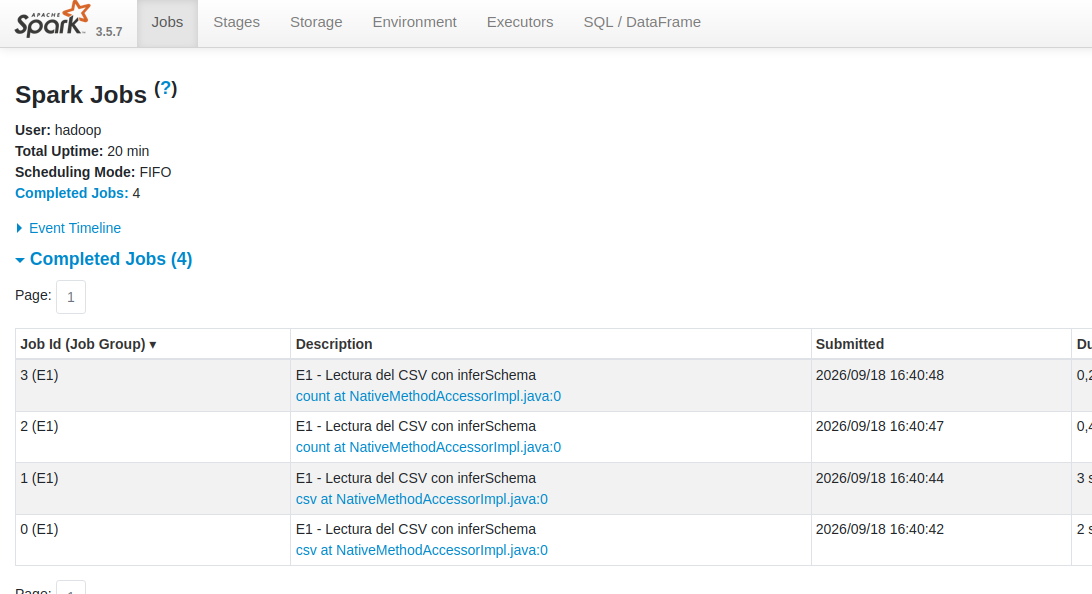

In [4]:
sc.setJobGroup("E2b", "E2b - Accion show(10) sobre la cadena")

df_wind.show(10, truncate=False)

+-------------------------------------+------------+-----------+------------------+------+
|name                                 |country_long|capacity_mw|commissioning_year|decada|
+-------------------------------------+------------+-----------+------------------+------+
|Ross Island                          |Antarctica  |1.0        |NULL              |NULL  |
|COMODORO RIVADAVIA - ANTONIO MORAN   |Argentina   |16.56      |NULL              |NULL  |
|GENERAL ACHA                         |Argentina   |1.8        |NULL              |NULL  |
|MAYOR BURATOVICH                     |Argentina   |2.02       |NULL              |NULL  |
|PARQUE EOLICO ARAUCO SAPEM I         |Argentina   |25.2       |NULL              |NULL  |
|PARQUE EOLICO ARAUCO SAPEM II        |Argentina   |25.2       |NULL              |NULL  |
|PARQUE EOLICO DIADEMA                |Argentina   |6.3        |NULL              |NULL  |
|PARQUE EOLICO EL TORDILLO            |Argentina   |3.0        |NULL              |NULL  |

**Registrar en la hoja (fila 3):** jobs con la etiqueta `E2a` al ejecutar la celda anterior (debería ser ninguno) · Job ID de `E2b` · número de stages · número de tareas de ese job.

*Predicción antes de mirar el portal:* ¿cuántos stages esperan que tenga este job, sabiendo que ninguna de las tres transformaciones mueve datos entre nodos? Anoten su predicción en la hoja antes de verificarla.

---
## Ejecución 3 — `count()` sobre el DataFrame completo

`count()` es una acción, no una transformación: obliga a Spark a recorrer todo el DataFrame.

In [6]:
sc.setJobGroup("E3", "E3 - count() sobre el DataFrame completo")

total = df.count()
print(f"Total de plantas: {total}")

Total de plantas: 34936


**Registrar en la hoja (fila 4):** cuántos Job ID aparecieron con la etiqueta `E3` · para cada uno, número de stages y tareas · si alguno de los stages aparece marcado como **Skipped** · Shuffle Write o Shuffle Read reportado, si hay alguno.

*Este es un buen punto para detenerse:* `count()` sobre un solo DataFrame, sin ningún `groupBy`, ¿debería mover datos entre executors? Comparen el tamaño (en bytes) y el motivo de ese shuffle con lo que van a ver en la Ejecución 4 — no si existe o no: eso se compara mejor contra la Ejecución 2, que no tiene ninguno.

**Dato para interpretar la tabla:** el valor de Shuffle Write de una stage y el de Shuffle Read de otra pueden coincidir exactamente — no es un error de registro. Son la misma información medida en los dos extremos del mismo shuffle: una stage escribe esos bytes a disco y otra, después, los lee. Si ven el mismo número en el Write de una stage y el Read de la siguiente, es la señal de que están viendo el mismo Exchange desde sus dos lados.

2 jobs con la etiqueta E3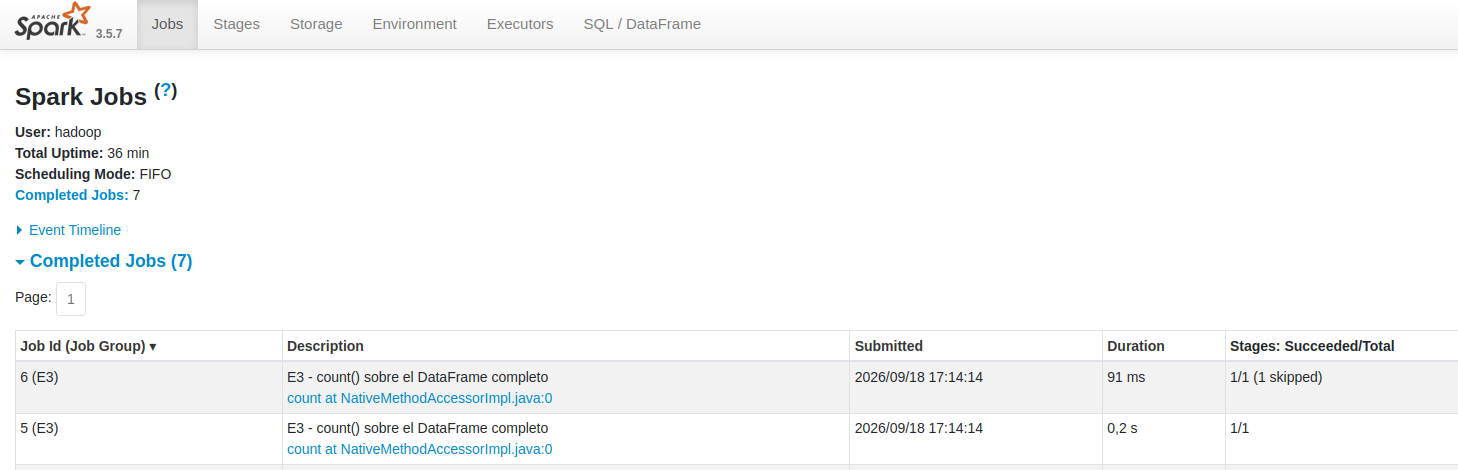 "\n" 
para la tarea 5 se realizaron 2 task y para la tarea 6 solo se creo un task

---
## Ejecución 4 — Agregación con shuffle

`groupBy` + `agg` + `orderBy`. A diferencia de la Ejecución 3, aquí el resultado agrupa por una columna categórica antes de ordenar — dos operaciones distintas que pueden requerir mover datos entre executors cada una.

In [7]:
sc.setJobGroup("E4", "E4 - groupBy + agg + orderBy con shuffle")

capacidad_por_fuel = (
    df.groupBy("primary_fuel")
      .agg(
          spark_sum("capacity_mw").alias("capacidad_total_mw"),
          count("*").alias("num_plantas")
      )
      .orderBy(col("capacidad_total_mw").desc())
)

capacidad_por_fuel.show(truncate=False)

+--------------+------------------+-----------+
|primary_fuel  |capacidad_total_mw|num_plantas|
+--------------+------------------+-----------+
|Coal          |1965540.9996000004|2330       |
|Gas           |1493050.6021489995|3998       |
|Hydro         |1053159.6197999984|7156       |
|Nuclear       |407911.75999999995|195        |
|Wind          |263053.7294999998 |5344       |
|Oil           |261878.7096180001 |2320       |
|Solar         |188312.32348999952|10665      |
|Biomass       |34281.30159999999 |1430       |
|Waste         |14748.713999999994|1068       |
|Geothermal    |12687.75          |189        |
|Cogeneration  |4048.0            |41         |
|Other         |3612.8599999999997|43         |
|Petcoke       |2424.5774999999994|12         |
|Storage       |1712.3000000000002|135        |
|Wave and Tidal|552.2             |10         |
+--------------+------------------+-----------+



**Registrar en la hoja (fila 5):** Job ID(s) con la etiqueta `E4` · stages de cada uno (¿cuántos, y cuántos *Skipped*?) · Shuffle Write y Shuffle Read en cada stage.

*Comparación obligatoria:* abran el **DAG Visualization** de este job y el del job de la Ejecución 2, uno al lado del otro. ¿En qué se diferencia la forma del grafo?

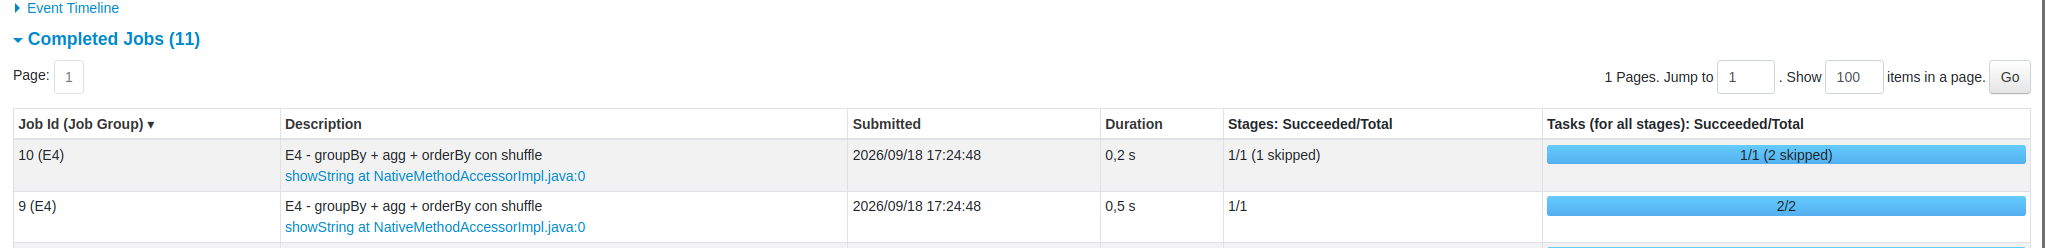
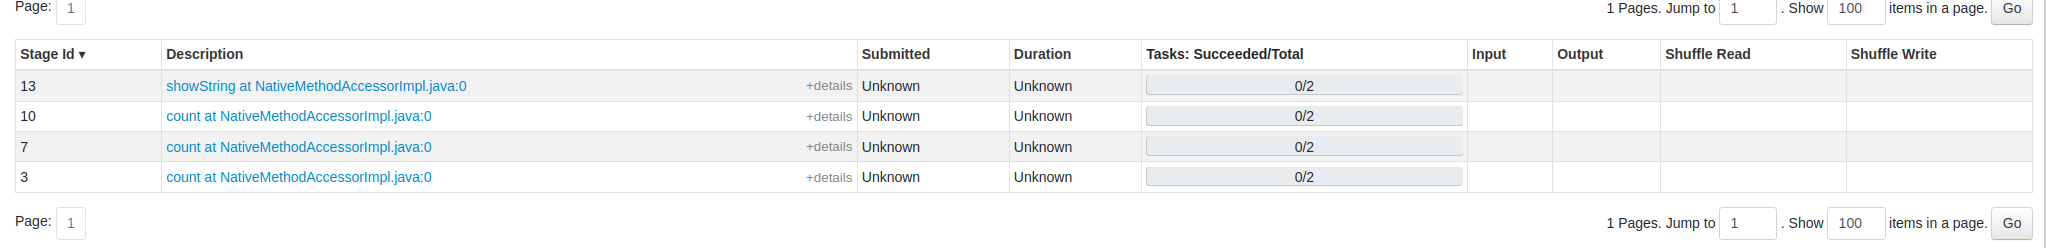

---
## Ejecución 5 — Materializar en memoria con `cache()`

Hasta ahora, cada vez que se pide un resultado sobre un DataFrame, Spark vuelve a leer el archivo y a recalcular — puede suceder inclusive si ya se calculó ese mismo resultado antes. `cache()` le indica a Spark que **conserve en memoria** el resultado de un DataFrame la primera vez que se materializa, para no recalcularlo en accesos posteriores.

Se hacen dos acciones sobre el mismo DataFrame cacheado: la primera paga el costo completo (lee, agrupa, ordena) y además almacena el resultado; la segunda debería aprovechar lo ya almacenado.

**Importante:** la señal de que el caché funcionó NO es que la segunda acción sea más rápida en segundos — acciones distintas (`count()` vs. `show()`) tardan tiempos distintos por su propia naturaleza, sin importar el caché. La señal confiable está en cómo cada stage obtiene sus datos de entrada: si dice **Shuffle Read**, los recalculó a través de un intercambio entre executors; si dice **Input**, los leyó directamente de donde `cache()` los dejó guardados.

**Nota — por qué no se reutiliza lo de la Ejecución 4.** Como se ha analizado en las sesiones de clase, Spark puede *saltarse* un stage (aparece como `Skipped`) cuando ya tiene el resultado de un cálculo anterior, sin necesidad de `cache()`. Es cierto — de hecho ya lo vieron en la Ejecución 4, entre los dos Job ID que generó esa única acción. Pero ese salto ocurre cuando dos *jobs* comparten literalmente el mismo objeto RDD/shuffle por dentro. Con el DataFrame API, cada acción nueva —aunque se llame sobre la misma variable— hace que Spark reconstruya el plan de ejecución desde cero. Por eso, aunque `capacidad_por_fuel` ya se había calculado por completo en la Ejecución 4, la primera acción de esta ejecución (E5a) recalcula todo otra vez: sin `cache()`, no hay atajo entre acciones separadas.

In [8]:
sc.setJobGroup("E5a", "E5a - cache() y primera accion (materializa)")

capacidad_cache = capacidad_por_fuel.cache()
capacidad_cache.count()

15

In [9]:
sc.setJobGroup("E5b", "E5b - segunda accion sobre el DataFrame YA cacheado")

capacidad_cache.show(truncate=False)

+--------------+------------------+-----------+
|primary_fuel  |capacidad_total_mw|num_plantas|
+--------------+------------------+-----------+
|Coal          |1965540.9996000004|2330       |
|Gas           |1493050.6021489995|3998       |
|Hydro         |1053159.6197999984|7156       |
|Nuclear       |407911.75999999995|195        |
|Wind          |263053.7294999998 |5344       |
|Oil           |261878.7096180001 |2320       |
|Solar         |188312.32348999952|10665      |
|Biomass       |34281.30159999999 |1430       |
|Waste         |14748.713999999994|1068       |
|Geothermal    |12687.75          |189        |
|Cogeneration  |4048.0            |41         |
|Other         |3612.8599999999997|43         |
|Petcoke       |2424.5774999999994|12         |
|Storage       |1712.3000000000002|135        |
|Wave and Tidal|552.2             |10         |
+--------------+------------------+-----------+



**Registrar en la hoja (fila 6), para E5a y E5b por separado:** ¿el stage completado muestra **Shuffle Read** o **Input** en la pestaña *Stages*? · si aparece `InMemoryTableScan` en el plan de la pestaña *SQL* (DAG).

*Lo que se espera observar:* que E5a muestre Shuffle Read (recalculó todo) y que E5b muestre Input en vez de Shuffle Read, con `InMemoryTableScan` reemplazando la lectura del CSV y el `Exchange` en su plan — porque ambos ya quedaron resueltos y almacenados por E5a. No comparen la duración en segundos: acciones distintas (`count()` vs. `show()`) cuestan tiempos distintos por sí mismas, sin relación con el caché.

**Aclaración sobre E5a:** van a ver **más de un Job ID** bajo la etiqueta `E5a` — es el mismo comportamiento de AQE que ya vieron en la Ejecución 4, solo que aquí hay más pasos porque se encadenan el shuffle del `groupBy` y el del `orderBy`. Cuéntenlos todos como parte de E5a. Además, la primera stage de esa cadena va a mostrar **Input** (porque ahí sí se lee el CSV directamente), no Shuffle Read — eso no contradice que E5a recalculó todo, lo confirma. Para responder esta fila, usen la **última** stage completada de E5a (la que produce el resultado final): esa es la que debe mostrar Shuffle Read.

---
## Ejecución 6 — Escritura y número de particiones

Se toma una porción del DataFrame original (no el resultado agrupado de la Ejecución 4, que tiene muy pocas filas) y se fuerza a 6 particiones con `repartition(6)`, para que el número de archivos generados sea observable con claridad. Luego se compara contra la misma escritura con `coalesce(1)`, que reduce el resultado a una sola partición antes de guardarlo.

In [10]:
# Cambiar <cod> por su cédula

sc.setJobGroup("E6a", "E6a - Escritura SIN coalesce (6 particiones)")

df.select("name", "country_long", "primary_fuel", "capacity_mw") \
  .repartition(6) \
  .write.csv("hdfs:///taller6_<cod>/sin_coalesce", header=True, mode="overwrite")

!hdfs dfs -ls /taller6_<cod>/sin_coalesce

/bin/bash: línea 1: cod: No existe el archivo o el directorio


In [11]:
sc.setJobGroup("E6b", "E6b - Escritura CON coalesce(1)")

df.select("name", "country_long", "primary_fuel", "capacity_mw") \
  .repartition(6).coalesce(1) \
  .write.csv("hdfs:///taller6_<cod>/con_coalesce", header=True, mode="overwrite")

!hdfs dfs -ls /taller6_<cod>/con_coalesce

/bin/bash: línea 1: cod: No existe el archivo o el directorio


**Registrar en la hoja (fila 7):** número de tareas del stage de escritura en cada caso · número de archivos `part-*` listados por `hdfs dfs -ls` en cada directorio.

**Aclaración:** en la pestaña *Stages* van a ver **dos filas** con la misma descripción (`E6a - Escritura SIN coalesce...` o `E6b - Escritura CON coalesce...`) — es la misma etiqueta de grupo aplicada a los dos jobs internos de la escritura (uno de lectura/reparto, otro de escritura real). No los distingan por el texto, que es igual en ambos: la stage de **escritura real** es la que tiene el número de tareas que coincide con el número de archivos `part-*` (6 para E6a, 1 para E6b); la otra, con menos tareas, es la que lee y reparte el DataFrame antes de escribir.

*Recuerden sustituir* `<cod>` *por su cédula en ambas rutas, como en el resto del curso.*

---
## Cierre

**No ejecuten `spark.stop()` todavía.** Mientras la aplicación siga activa, pueden volver a cualquier pestaña del portal para completar un dato que les haya faltado. Solo se detiene la sesión cuando ladocente lo indique, al cierre de la Fase 1.

In [12]:
# No ejecutar hasta que la docente lo indique.
# spark.stop()